In [1]:
print("Google Colab is working!")

Google Colab is working!


In [2]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

gpu = tf.config.list_physical_devices('GPU')

print("Available GPUs:", gpu)

TensorFlow Version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "plant_village",
    with_info=True,
    as_supervised=True
)

print("Dataset loaded successfully!")
print("Number of classes:", info.features["label"].num_classes)
print("Class names:", info.features["label"].names)

ModuleNotFoundError: No module named 'importlib_resources'

In [4]:
!pip install -q importlib_resources

In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
dataset, info = tfds.load(
    "plant_village",
    with_info=True,
    as_supervised=True
)

print("Dataset loaded successfully!")
print("Total classes:", info.features["label"].num_classes)
print("Class names:", info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.VAQ7RU_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded successfully!
Total classes: 38
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy

In [3]:
train_dataset, validation_dataset = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    shuffle_files=True
)

print("Training dataset:", train_dataset)
print("Validation dataset:", validation_dataset)

Training dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>


In [6]:
import matplotlib.pyplot as plt
import numpy as np

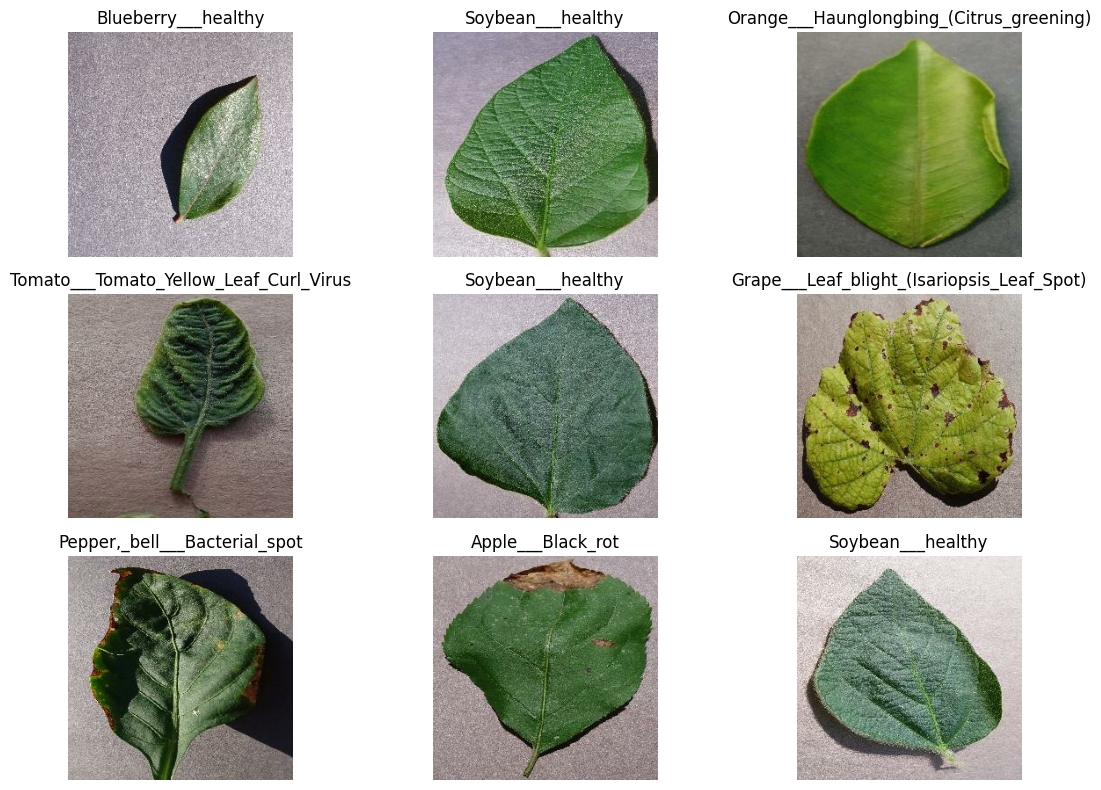

In [7]:
class_names = info.features["label"].names

plt.figure(figsize=(12, 8))

for i, (image, label) in enumerate(train_dataset.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

def preprocess_image(image, label):
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

train_dataset = train_dataset.map(preprocess_image)
validation_dataset = validation_dataset.map(preprocess_image)

print("Preprocessing completed!")

Preprocessing completed!


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = (
    train_dataset
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

validation_dataset = (
    validation_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Dataset batching completed!")

Dataset batching completed!


In [10]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [11]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.2),

    layers.Dense(38, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [14]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 129s 75ms/step - accuracy: 0.6468 - loss: 1.4428 - val_accuracy: 0.8647 - val_loss: 0.6275
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 84s 48ms/step - accuracy: 0.8702 - loss: 0.5358 - val_accuracy: 0.9100 - val_loss: 0.3831
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 66s 48ms/step - accuracy: 0.9045 - loss: 0.3735 - val_accuracy: 0.9277 - val_loss: 0.2935
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 75s 55ms/step - accuracy: 0.9220 - loss: 0.2984 - val_accuracy: 0.9351 - val_loss: 0.2477
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 66s 48ms/step - accuracy: 0.9320 - loss: 0.2553 - val_accuracy: 0.9402 - val_loss: 0.2191
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 75s 54ms/step - accuracy: 0.9383 - loss: 0.2258 - val_accuracy: 0.9456 - val_loss: 0.1989
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 75s 55ms/step - accuracy: 0.9432 - loss: 0.2050 - val_accuracy: 0.9486 - val_loss: 0.1846
Epoch 8/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 66s 48ms/step - accuracy: 0.9468 

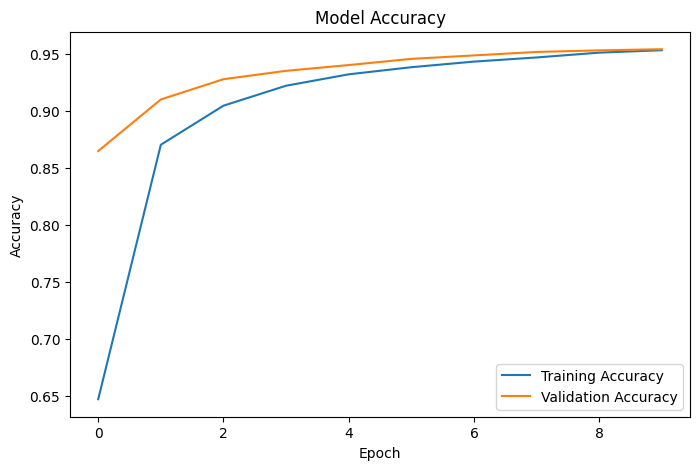

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [16]:
model.save("leaf_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [17]:
from google.colab import files

files.download("leaf_disease_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from google.colab import files

uploaded = files.upload()


Saving test.webp to test.webp


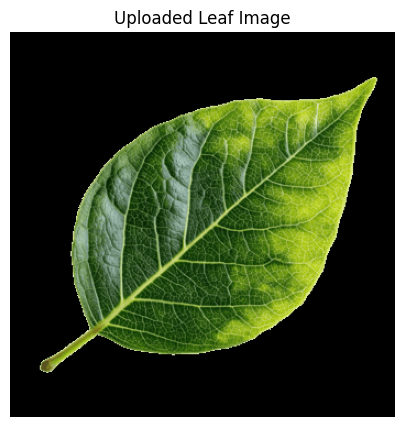

In [19]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("test.webp").convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Uploaded Leaf Image")
plt.show()

In [20]:
img_array = tf.keras.utils.img_to_array(img)

img_array = tf.image.resize(img_array, (224, 224))

img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array)

predicted_class = np.argmax(predictions[0])

print("Predicted Disease:", class_names[predicted_class])
print("Confidence:", round(float(np.max(predictions[0])) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step
Predicted Disease: Blueberry___healthy
Confidence: 70.89 %


In [21]:
loss, accuracy = model.evaluate(validation_dataset)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Validation Loss:", round(loss, 4))

340/340 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.9541 - loss: 0.1566
Validation Accuracy: 95.41 %
Validation Loss: 0.1566


In [22]:
!pip install -q scikit-learn

In [24]:
y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.95      0.95      0.95       129
                            Apple___Black_rot       0.99      0.96      0.98       154
                     Apple___Cedar_apple_rust       0.98      0.96      0.97        54
                              Apple___healthy       0.98      0.99      0.98       339
                          Blueberry___healthy       1.00      1.00      1.00       292
                             Cherry___healthy       0.98      0.99      0.99       195
                      Cherry___Powdery_mildew       0.99      0.98      0.98       201
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.83      0.79      0.81       108
                           Corn___Common_rust       0.99      1.00      1.00       239
                               Corn___healthy       1.00      1.00      1.00       223
                  Corn___Northern_Leaf_Bli

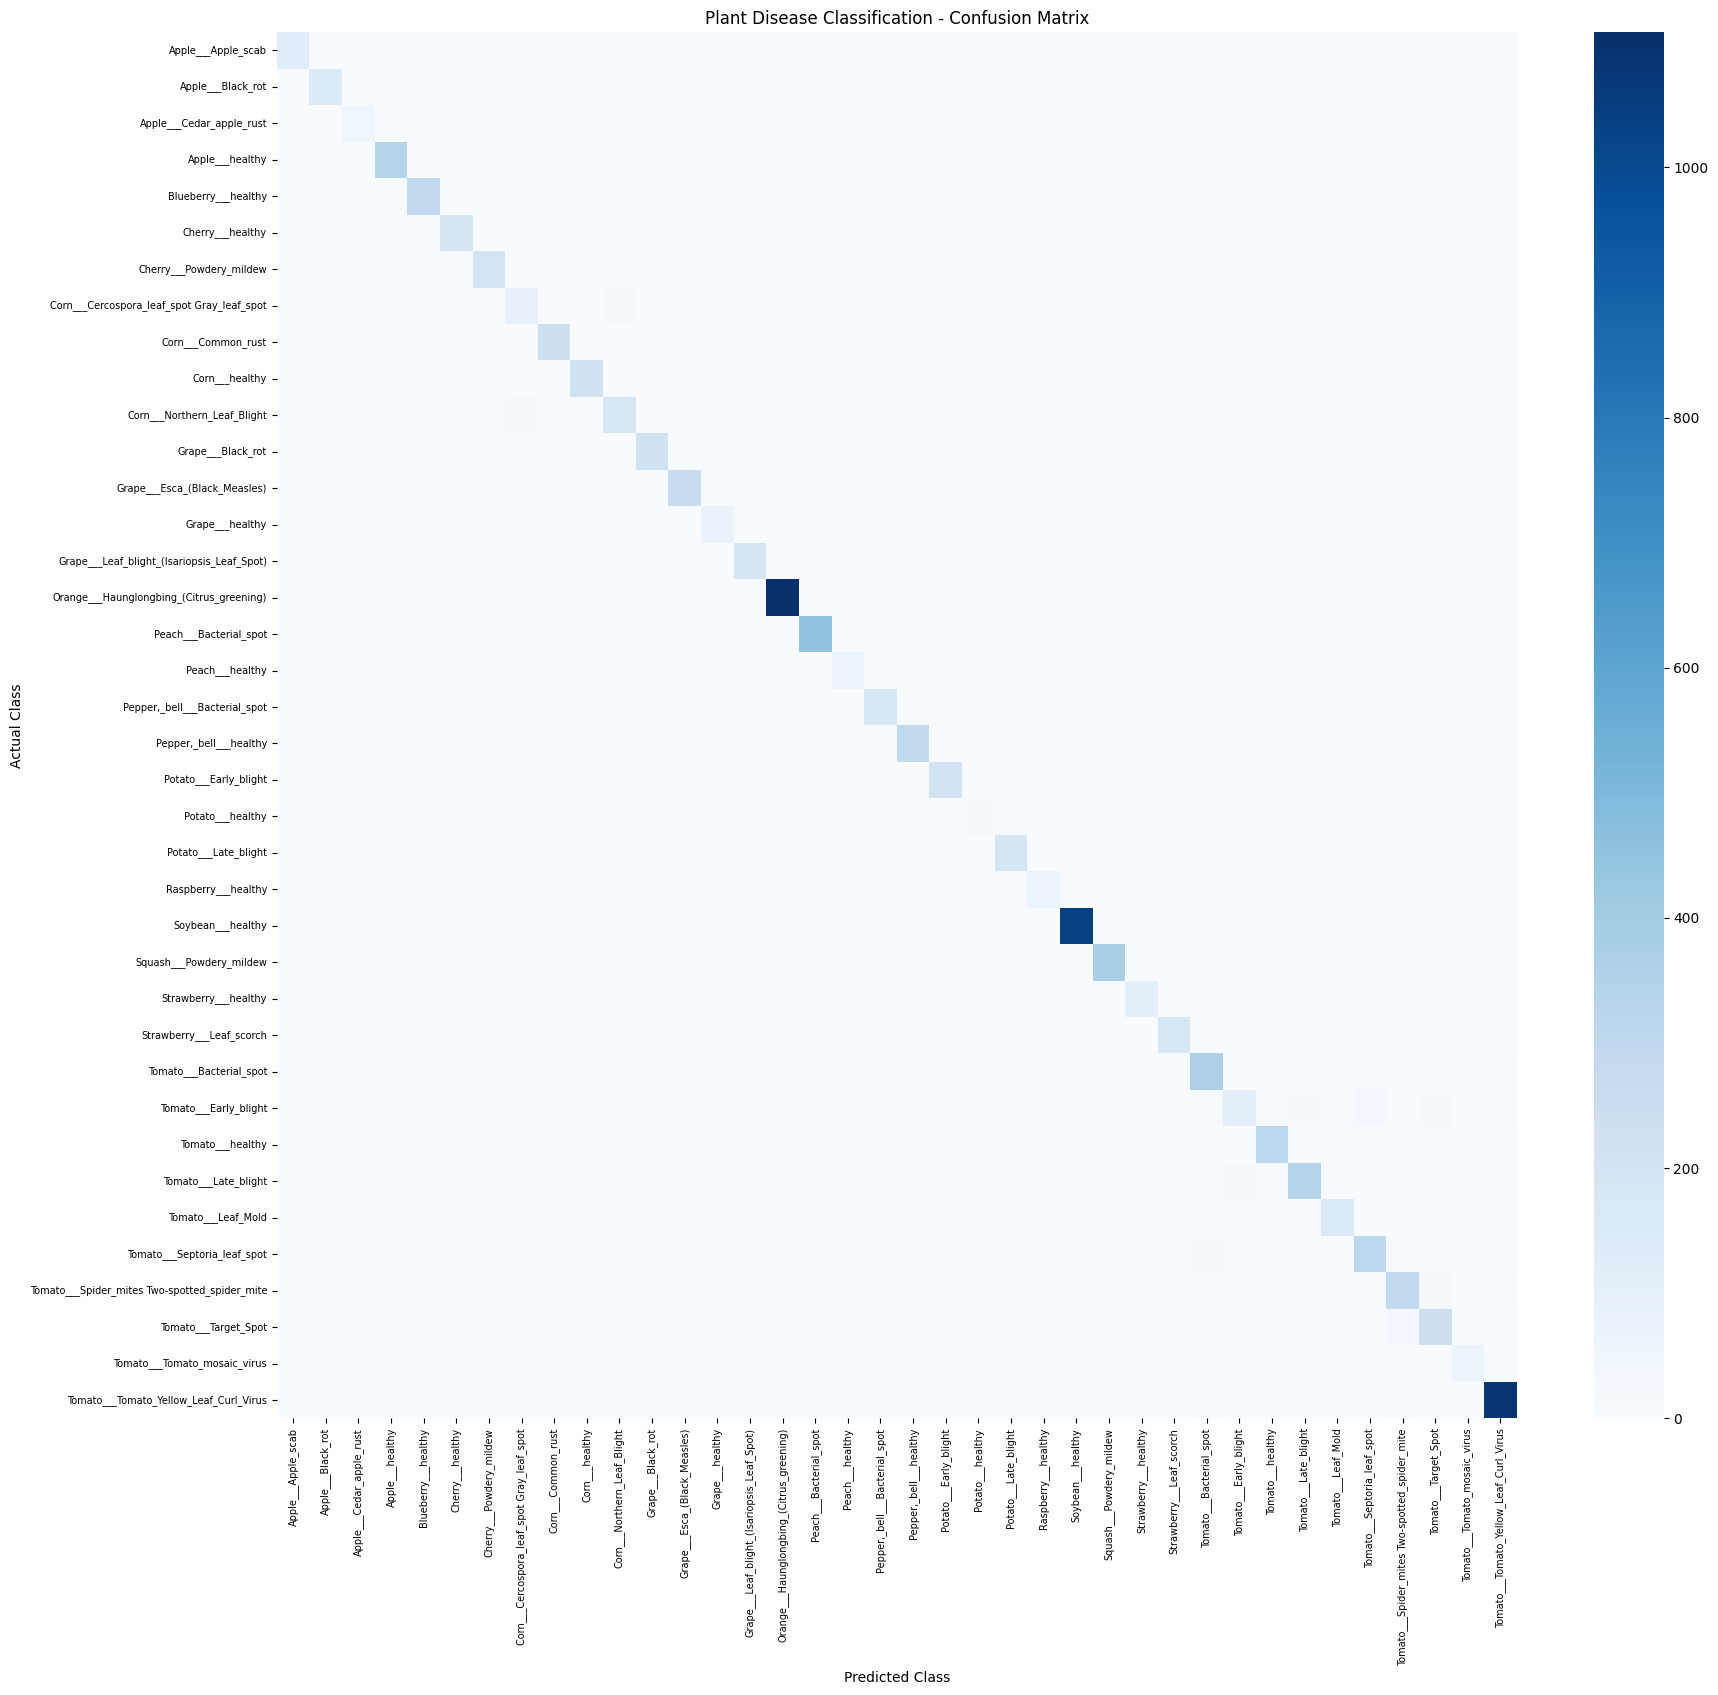

In [25]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(20, 18))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names,
            yticklabels=class_names)

plt.title("Plant Disease Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.show()